# Ariketa 3.5 — SVM (Euskarri-Bektoreen Makinak) ⚙️ (EGITEKO)

Orain arte:

```text
Erabaki-zuhaitza → arauak
KNN              → auzokideak / distantziak
Logistika        → probabilitatea + muga lineala
```

Orain beste galdera bat egingo dugu:

> **Bi klase bereizteko muga bat baino gehiago badago, zein da mugarik sendoena?**

SVM-ren ideia nagusia:

> **Klaseen artean ahalik eta marjina zabalena uzten duen muga bilatzea.**

Eta arazoa linealki bereizgarria ez bada:

> **kernel bat erabil dezakegu muga ez-lineala lortzeko.**

### Saioaren ibilbidea

```text
1. Muga lineala
2. Marjina maximoa
3. Euskarri-bektoreak
4. decision_function()
5. C: akatsak vs marjina
6. Arazo ez-lineala
7. Kernel RBF
8. gamma
9. Titanic benetako datuekin
```


## 📝 Nola egin

- 🟢 **EMANDA:** exekutatu eta ulertu.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU ZEROTIK:** zati osoa idatzi.

Helburua ez da parametroak buruz ikastea, baizik eta **SVM-k muga nola aukeratzen duen ulertzea**.


# 0 ATALA — Logistic Regression → SVM zubia 🟢

Logistic Regression-en ikusi dugu:

```text
features
↓
z = w·x + b
↓
sigmoid
↓
probabilitatea
↓
0.5 atalasea
↓
klasea
```

Bi klase ditugunean Logistic Regression-ek **muga lineal bat** ikas dezake.

SVM linealak ere muga lineala ikasten du, baina helburua desberdina da:

| Logistic Regression | SVM lineala |
|---|---|
| probabilitateak modelatzen ditu | bereizketa-muga modelatzen du |
| Log Loss minimizatzen du | marjina handitzen saiatzen da |
| `predict_proba()` naturala | `decision_function()` naturala |
| datu guztiek loss-ean parte hartzen dute | mugatik gertuko puntuak bereziki garrantzitsuak dira |

> **Biak linealak izan daitezke, baina ez dute muga modu berean ikasten.**


## 0.1 — Liburutegiak 🟢


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Erabaki-eremua marrazteko helper-a
def marraztu_muga(modeloa, X, y, izenburua, ax):
    x0 = X[:, 0].min() - 0.6
    x1 = X[:, 0].max() + 0.6
    y0 = X[:, 1].min() - 0.6
    y1 = X[:, 1].max() + 0.6

    xx, yy = np.meshgrid(
        np.linspace(x0, x1, 300),
        np.linspace(y0, y1, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = modeloa.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap='coolwarm')
    ax.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap='coolwarm',
        edgecolors='k', s=30
    )

    ax.set_title(izenburua)


# 1 ATALA — SVM lineala: zein muga aukeratu? 🟢🟡

Lehenengo datu errazak sortuko ditugu: bi multzo bereizgarri.

Pentsa hainbat zuzenek bi klaseak ondo bana ditzaketela.

SVM-k ez du edozein zuzen aukeratzen:

> **bi klaseetatik ahalik eta urrunen dagoen muga bilatzen du.**

Distantzia libre horri **marjina** deitzen diogu.


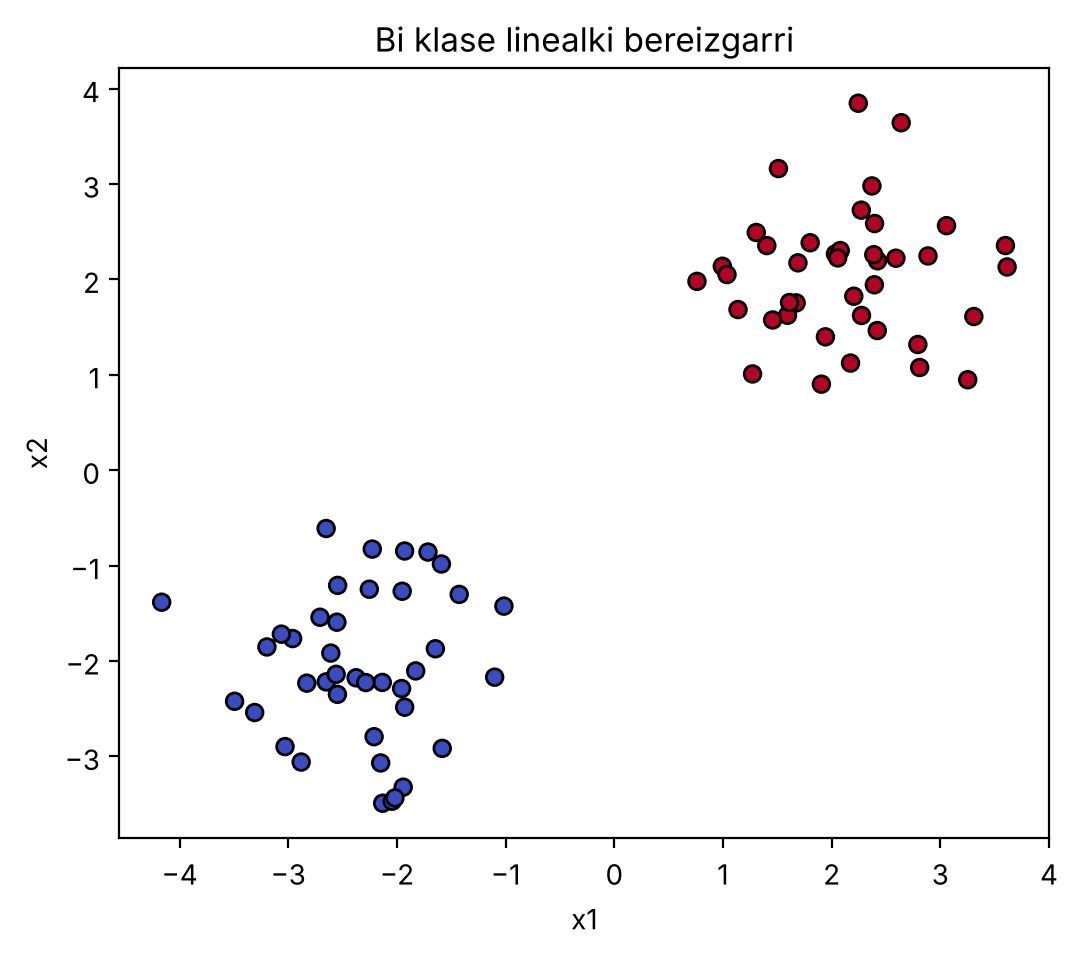

In [2]:
# Bi klase nahiko garbi
Xb, yb = make_blobs(
    n_samples=80,
    centers=[(-2.2, -2.0), (2.2, 2.0)],
    cluster_std=0.75,
    random_state=42
)

plt.figure(figsize=(6, 5))
plt.scatter(Xb[:, 0], Xb[:, 1], c=yb, cmap='coolwarm', edgecolors='k')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Bi klase linealki bereizgarri')
plt.show()


## 1.1 — Muga posible asko 🟢

Grafikoan hiru zuzen ikusiko ditugu.

Galdera:

> **Zein zuzenek uzten du bi klaseen arteko “korridore” zabalena?**

Oraindik ez dugu SVM entrenatuko; intuizio geometrikoa eraikitzen ari gara.


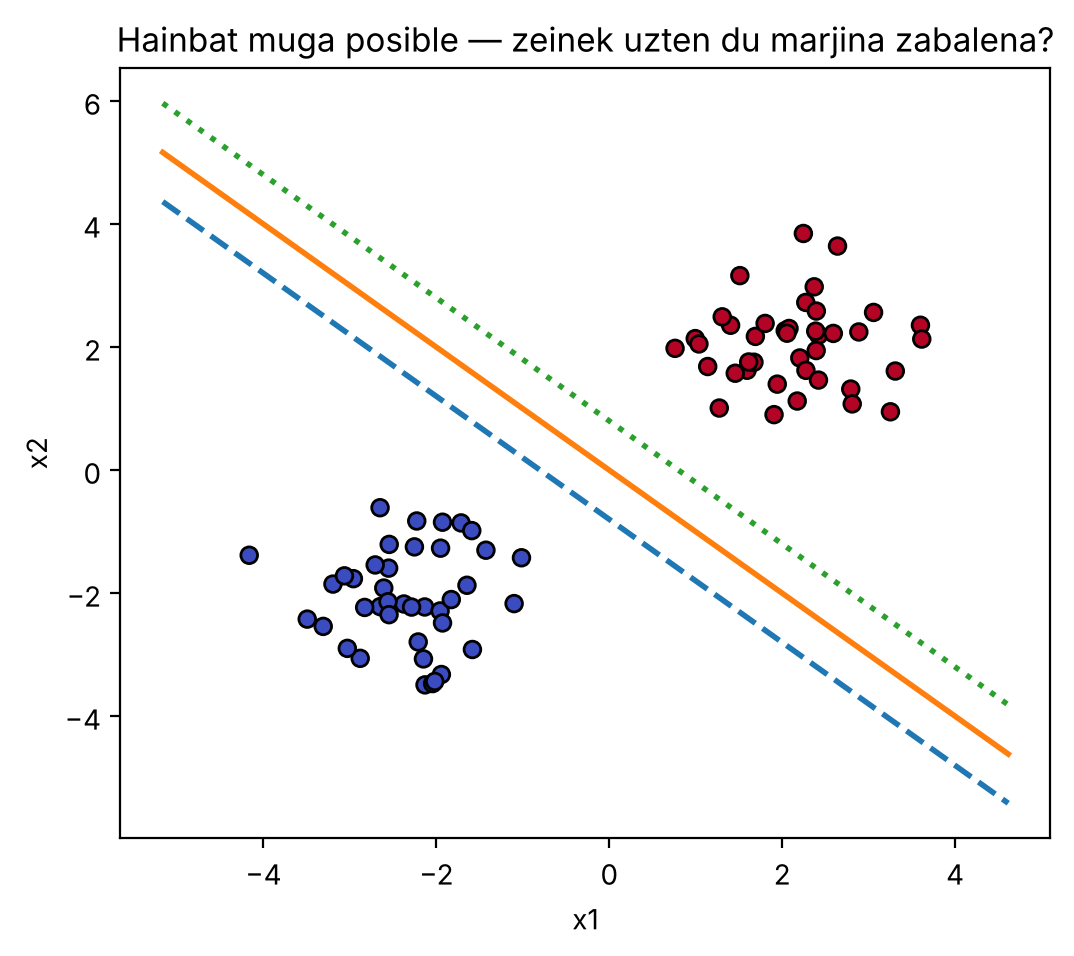

In [3]:
plt.figure(figsize=(6, 5))
plt.scatter(Xb[:, 0], Xb[:, 1], c=yb, cmap='coolwarm', edgecolors='k')

xx = np.linspace(Xb[:, 0].min()-1, Xb[:, 0].max()+1, 200)

# Hiru muga posible ilustratzeko
for b0, estilo in [(-0.8, '--'), (0.0, '-'), (0.8, ':')]:
    yy = -xx + b0
    plt.plot(xx, yy, estilo, linewidth=2)

plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Hainbat muga posible — zeinek uzten du marjina zabalena?')
plt.show()


## 1.2 — Marjina maximoa eta euskarri-bektoreak 🟢

Orain SVM lineala entrenatuko dugu.

Grafikoan:

```text
lerro jarraitua → decision boundary, score = 0
lerro etenak    → marjinaren ertzak, score = -1 eta +1
zirkulu handiak → support vectors / euskarri-bektoreak
```

### Zer dira euskarri-bektoreak?

Datu garbi eta linealki bereizgarrietan, marjinaren ertzetik gertuen dauden puntuak dira.

Puntu horiek dira bereziki garrantzitsuak muga definitzeko.

> **SVM izena hortik dator: Support Vector Machine.**

Datu errealetan support vector batzuk marjinaren barruan edo oker sailkatuta ere egon daitezke.


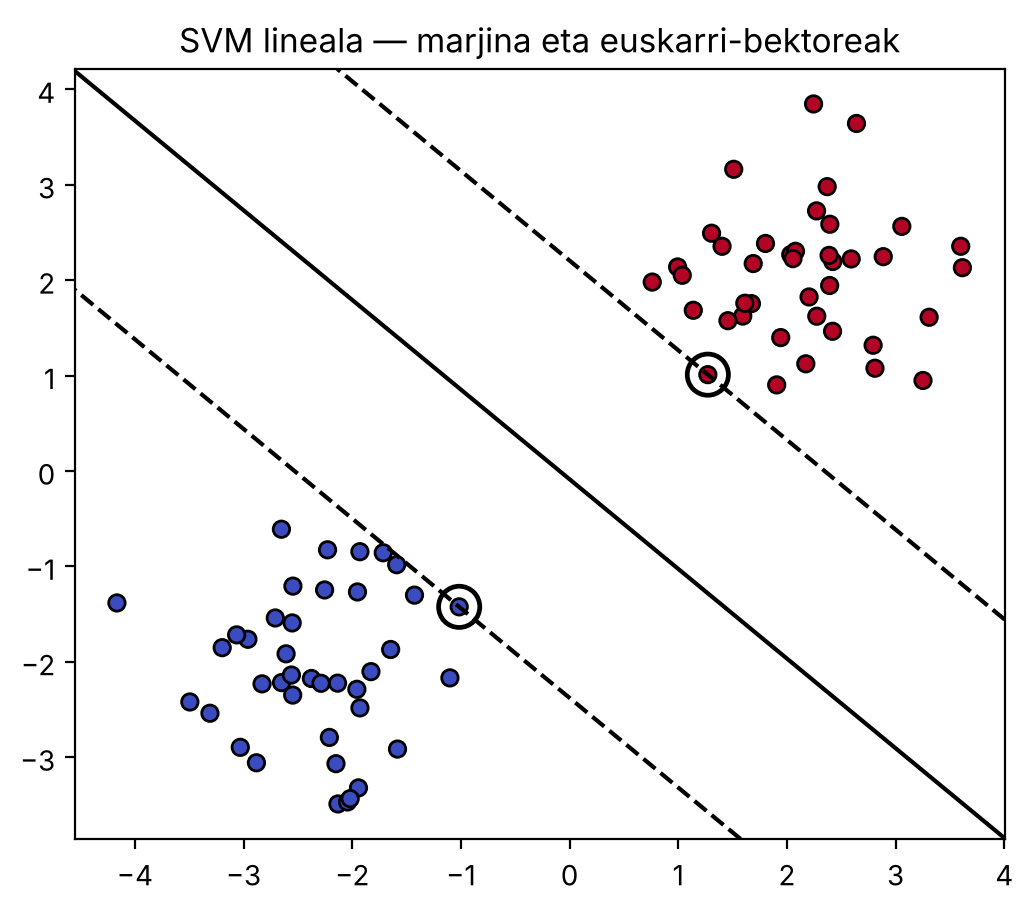

Support vector kopurua: 2


In [4]:
# bete ____ : SVM lineala
svm_lin = SVC(kernel='linear', C=10)
svm_lin.fit(Xb, yb)

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    Xb[:, 0], Xb[:, 1],
    c=yb, cmap='coolwarm',
    edgecolors='k', s=35
)

# Sare bat sortu decision_function ikusteko
xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx = np.linspace(xlim[0], xlim[1], 250)
yy = np.linspace(ylim[0], ylim[1], 250)
YY, XX = np.meshgrid(yy, xx)

grid = np.c_[XX.ravel(), YY.ravel()]

# SVM score-a
Z = svm_lin.decision_function(grid).reshape(XX.shape)

# -1 eta +1 = marjinaren ertzak; 0 = muga
ax.contour(
    XX, YY, Z,
    levels=[-1, 0, 1],
    colors='k',
    linestyles=['--', '-', '--']
)

# bete ____ : euskarri-bektoreak
sv = svm_lin.support_vectors_

ax.scatter(
    sv[:, 0], sv[:, 1],
    s=220,
    facecolors='none',
    edgecolors='k',
    linewidths=1.7
)

ax.set_title('SVM lineala — marjina eta euskarri-bektoreak')
plt.show()

print('Support vector kopurua:', len(sv))


## 1.3 — `decision_function()`: mugaren zein aldetan dago puntua? 🟢

Logistic Regression-ek probabilitatea ematen zuen:

```text
0 -------- 0.5 -------- 1
             ↑
          atalasea
```

SVM-k modu naturalean **decision score** bat ematen du:

```text
klase 0 aldean          klase 1 aldean
      ←──────── 0 ────────→
               ↑
             muga
```

Orokorrean, sailkapen bitarrean:

```text
score < 0 → klase 0 aldean
score > 0 → klase 1 aldean
score ≈ 0 → mugatik gertu
```

Zenbat eta `|score|` handiagoa, orduan eta urrunago dago puntua mugatik.

> Hau **ez da probabilitatea**.


In [5]:
# Datuetako lehen 8 puntuen decision score-ak
scores = svm_lin.decision_function(Xb[:8])

for i, (score, klasea) in enumerate(zip(scores, yb[:8])):
    print(
        f'Puntua {i:>2}: '
        f'score={score:>6.2f} | '
        f'benetako klasea={klasea}'
    )


Puntua  0: score=  2.64 | benetako klasea=1
Puntua  1: score=  2.16 | benetako klasea=1
Puntua  2: score= -1.87 | benetako klasea=0
Puntua  3: score= -1.32 | benetako klasea=0
Puntua  4: score=  2.71 | benetako klasea=1
Puntua  5: score= -2.18 | benetako klasea=0
Puntua  6: score=  2.20 | benetako klasea=1
Puntua  7: score=  1.99 | benetako klasea=1


# 2 ATALA — Soft margin eta `C` 🟢🟡

Benetako datuak ez dira beti perfektuki bereizgarriak.

Batzuetan bi klaseetako puntuak nahasten dira:

```text
● ● ○ ●
● ○ ○ ○
```

Orduan SVM-k konpromiso bat behar du:

```text
marjina zabala
VS
training akats gutxi
```

`C` parametroak konpromiso hori kontrolatzen du.

### Intuizioa

```text
C TXIKIA
→ akats batzuk onartzen ditu
→ marjina zabalagoa
→ erregularizazio handiagoa
→ muga leunagoa

C HANDIA
→ training akatsak gogor zigortzen ditu
→ puntu gehiagori egokitzen saiatzen da
→ marjina estuagoa izan daiteke
→ overfitting arrisku handiagoa
```

Gogoratzeko:

> **C = zenbat zigortu nahi ditugu training akatsak?**


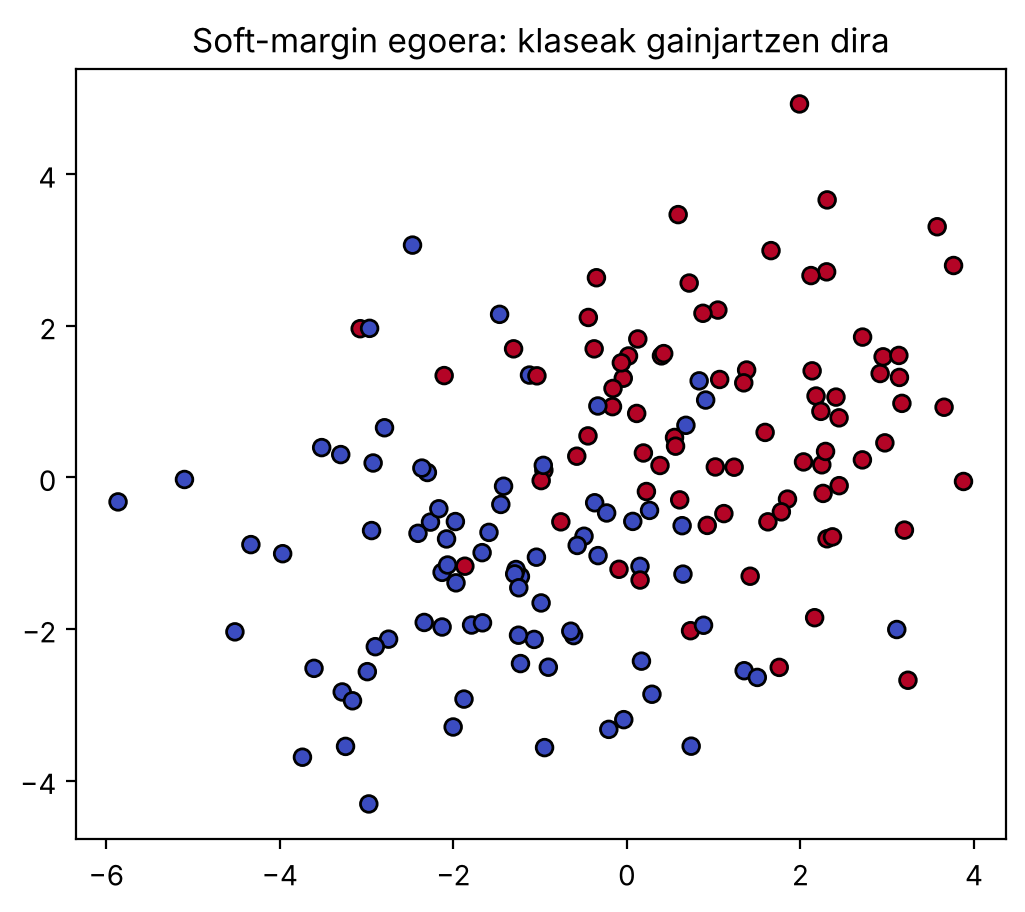

In [6]:
# Orain klaseak gehiago nahasten ditugu
Xo, yo = make_blobs(
    n_samples=160,
    centers=[(-1.3, -1.1), (1.3, 1.1)],
    cluster_std=1.45,
    random_state=12
)

plt.figure(figsize=(6, 5))
plt.scatter(Xo[:, 0], Xo[:, 1], c=yo, cmap='coolwarm', edgecolors='k')
plt.title('Soft-margin egoera: klaseak gainjartzen dira')
plt.show()


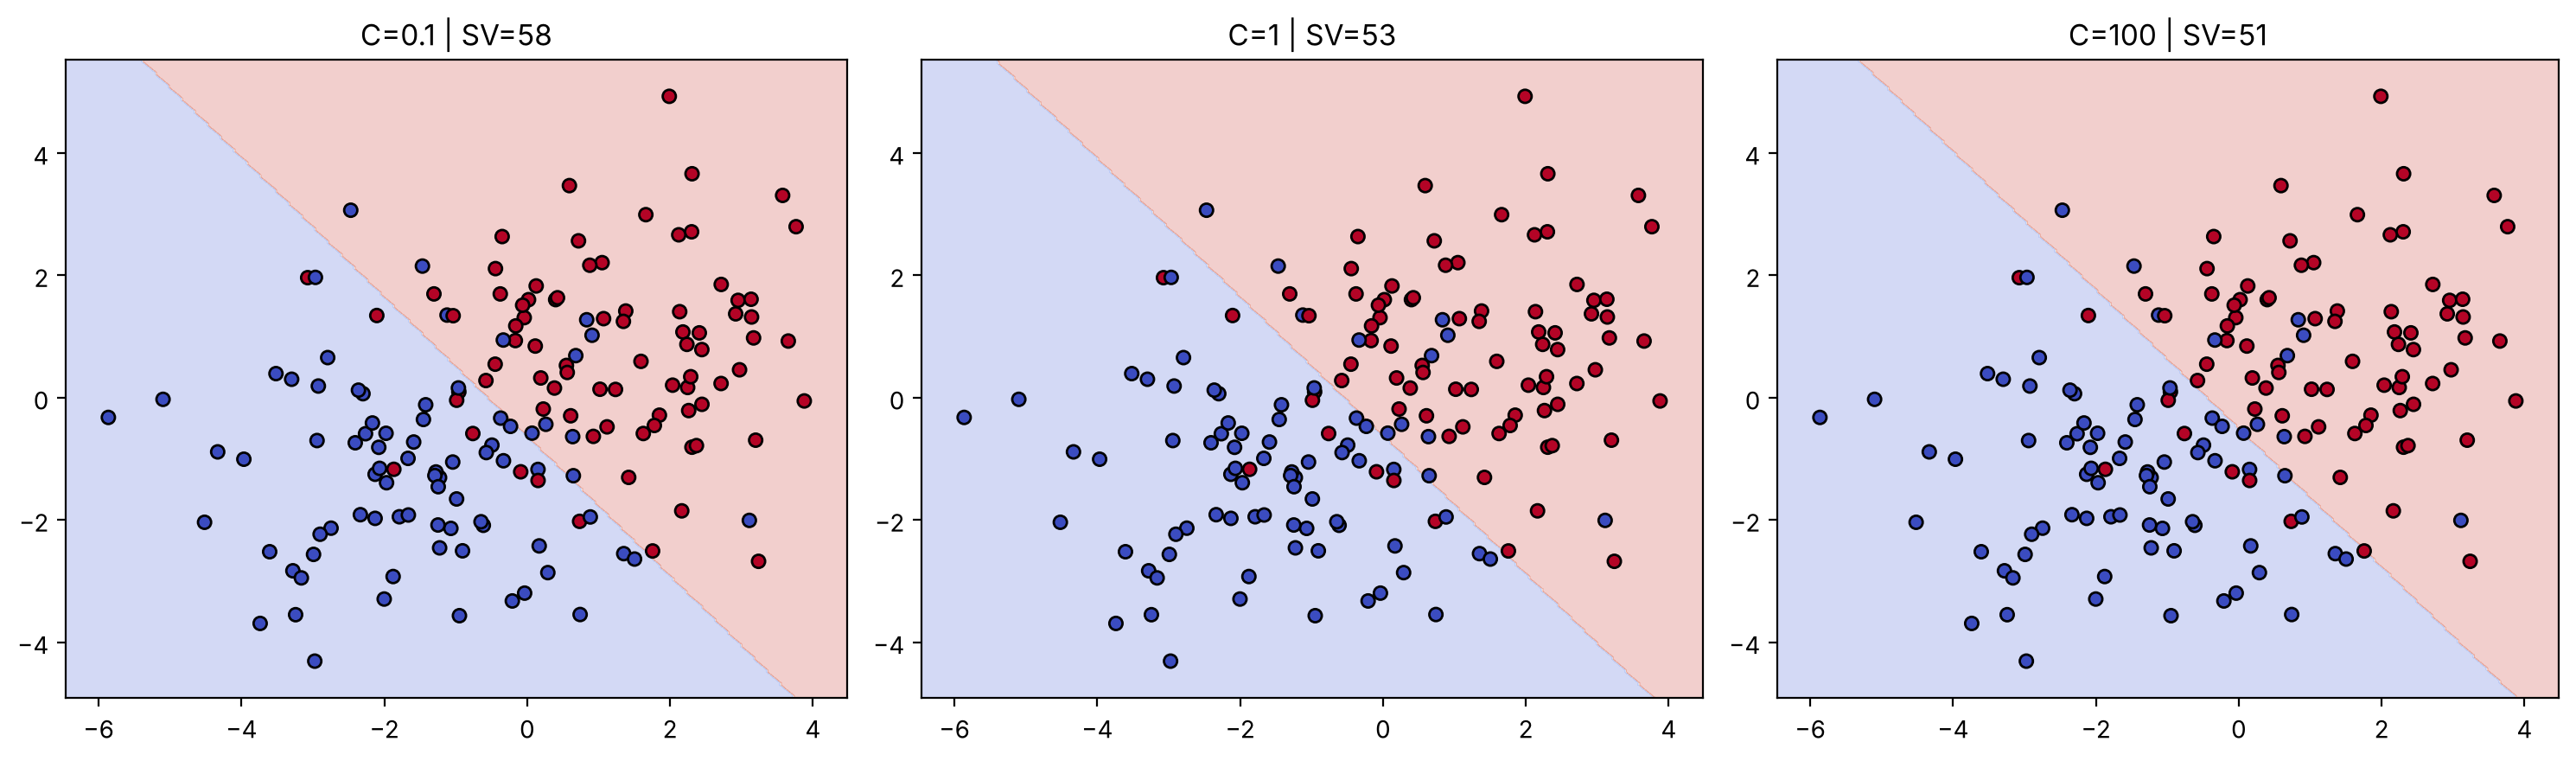

In [7]:
# Hutsuneak bete:
C_balioak = [0.1, 1, 100]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, c in zip(axes, C_balioak):

    modeloa = SVC(
        kernel='linear',
        C=c
    )

    modeloa.fit(Xo, yo)

    marraztu_muga(
        modeloa,
        Xo,
        yo,
        f'C={c} | SV={len(modeloa.support_vectors_)}',
        ax
    )

plt.tight_layout()
plt.show()


### Hausnartu

- `C=0.1` → zer gertatzen da mugarekin?
- `C=100` → zer gertatzen da training puntuetara egokitzearekin?
- Zein kasutan espero zenuke overfitting arrisku handiagoa?


**Erantzunak:**

- **C=0.1** → akatsak gutxi zigortzen dira: marjina **zabala** eta muga **leuna**; puntu asko geratzen dira marjina barruan, beraz **support vector gehiago** daude (58). Erregularizazio handia.
- **C=100** → training akatsak gogor zigortzen dira: muga puntu gehiago ondo sailkatzen saiatzen da, marjina **estuagoa** da eta support vector gutxiago daude (51).
- **Overfitting arrisku handiagoa C=100-ekin**: train-eko puntu zehatzetara gehiago egokitzen da (zarata barne).

Oharra: kernel lineala denez, mugak zuzen bat izaten jarraitzen du hiru kasuetan; aldatzen dena **posizioa eta marjinaren zabalera** dira.

# 3 ATALA — Arazo ez-lineala: zuzen batek ezin du 🟢

Orain `make_circles` erabiliko dugu.

Hau **sailkapen gainbegiratuko** adibidea da: `y` etiketak ezagutzen ditugu.

Forma hau anomalia-detekzioaren egoera batzuekin lotu daiteke intuitiboki, baina **ez dugu hemen anomaly detection algoritmo bat entrenatzen**.

Galdera:

> **Marraztu al dezakezu zuzen bakar bat barruko zirkulua eta kanpoko eraztuna bereizteko?**

Ez.

Horregatik Logistic Regression linealak eta SVM linealak arazoak izango dituzte.


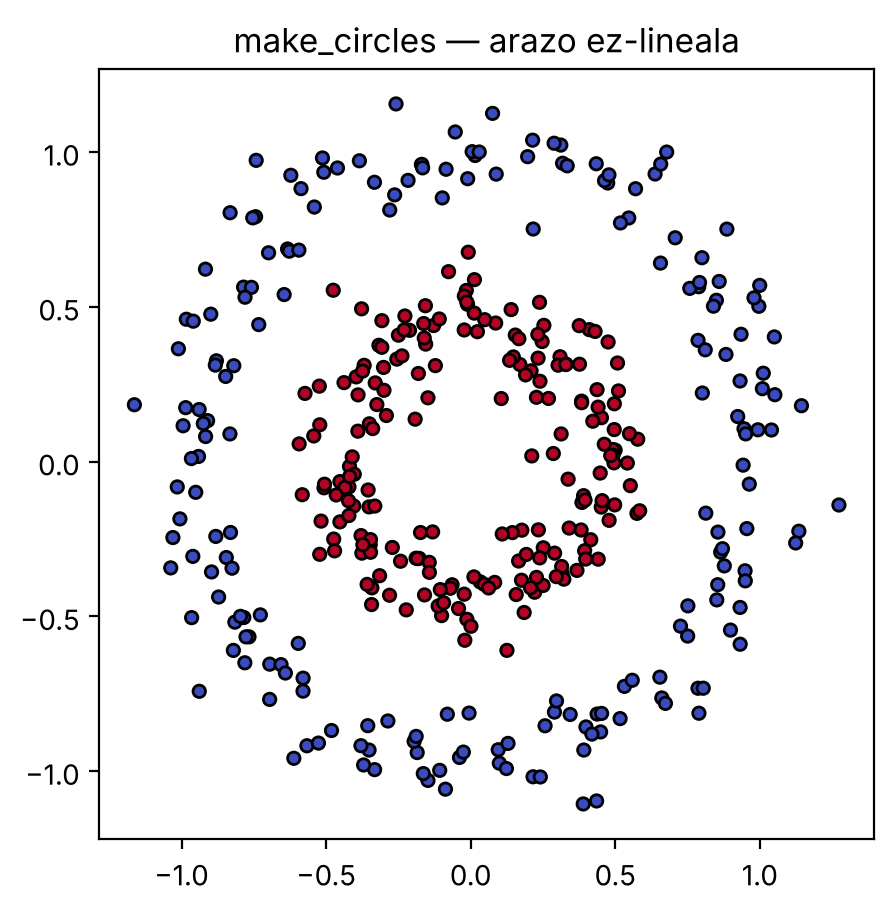

In [8]:
Xc, yc = make_circles(
    n_samples=400,
    noise=0.09,
    factor=0.45,
    random_state=42
)

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc,
    yc,
    test_size=0.25,
    random_state=42,
    stratify=yc
)

plt.figure(figsize=(5, 5))
plt.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap='coolwarm', edgecolors='k', s=20)
plt.title('make_circles — arazo ez-lineala')
plt.show()


Logistika    TEST accuracy: 0.550
SVM lineala  TEST accuracy: 0.520


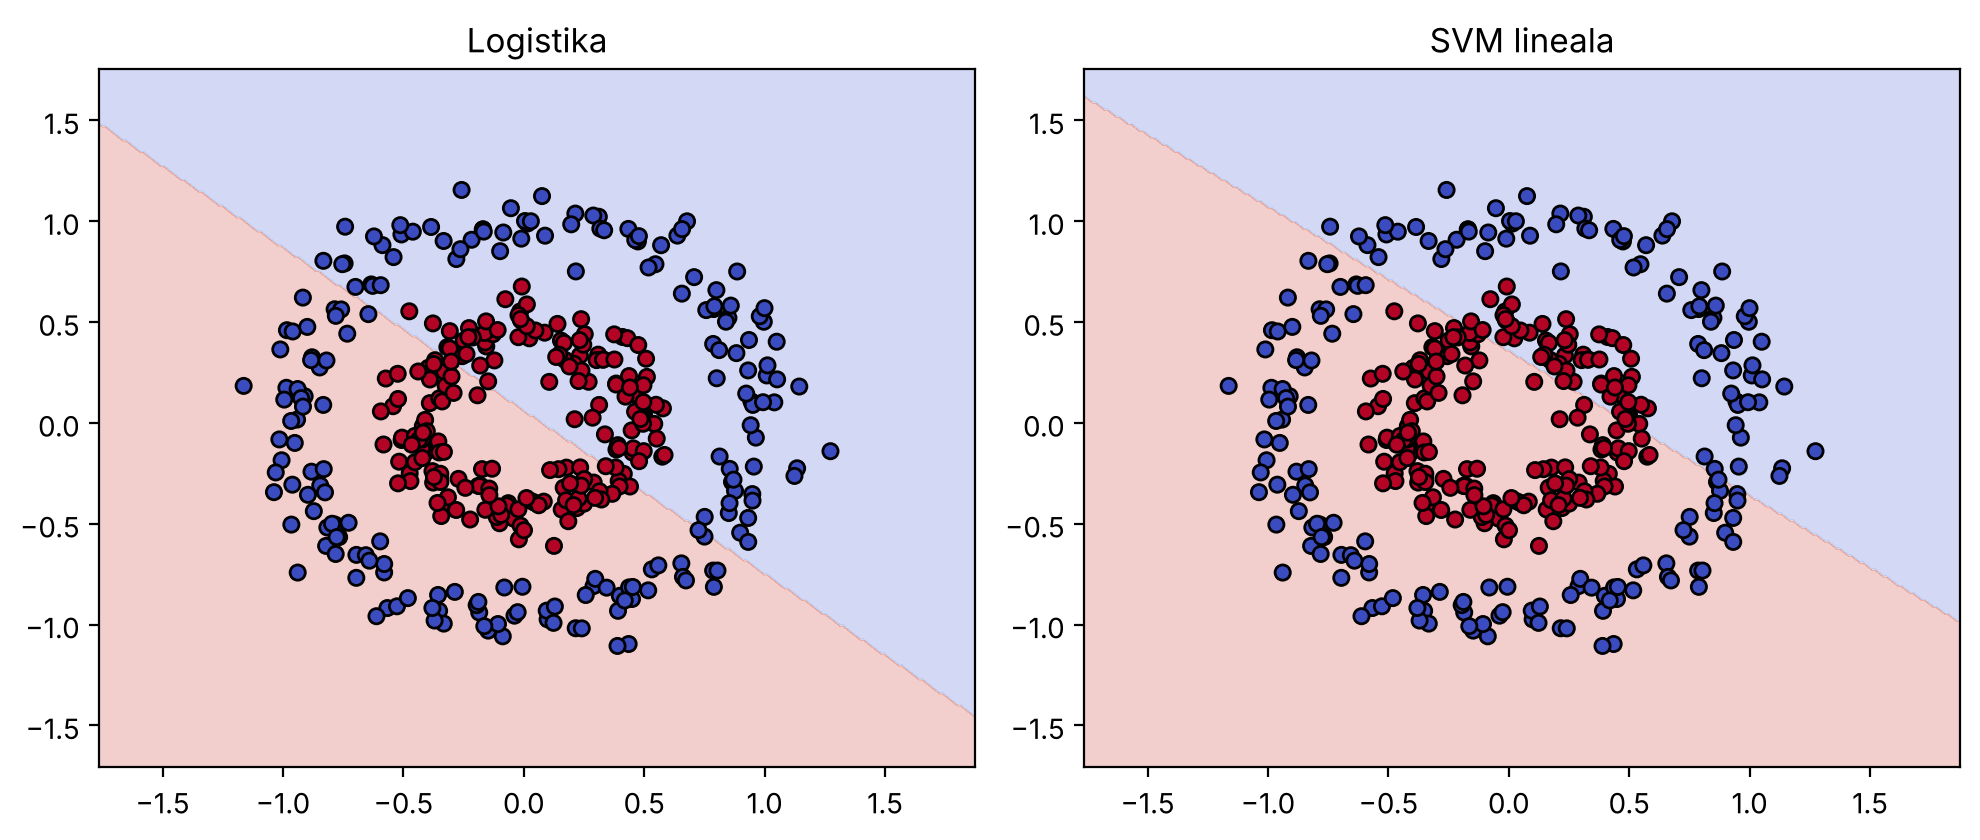

In [9]:
modeloak = [
    ('Logistika', LogisticRegression()),
    ('SVM lineala', SVC(kernel='linear'))
]

for izena, modeloa in modeloak:
    modeloa.fit(Xc_tr, yc_tr)

    acc = modeloa.score(
        Xc_te,
        yc_te
    )

    print(f'{izena:12s} TEST accuracy: {acc:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))

for ax, (izena, modeloa) in zip(axes, modeloak):
    marraztu_muga(modeloa, Xc, yc, izena, ax)

plt.tight_layout()
plt.show()


## 3.1 — Kernelaren intuizioa: beste ikuspegi batetik begiratu 🟢

Zirkuluen arazoa 2D-n ez da linealki bereizgarria.

Baina ezaugarri berri bat asmatuko bagenu:

$$
r^2 = x_1^2 + x_2^2
$$

barruko puntuek `r²` txikia izango lukete eta kanpokoek `r²` handiagoa.

Beraz:

```text
2D espazioa
↓
beste feature-space batera begiratu
↓
bereizketa errazagoa
```

### Kontuz

RBF kernelak **ez du zehazki `r²` zutabe hau sortzen**.

Adibide honek kernel-trick-aren ideia ulertzeko balio du:

> **datuak beste feature-space batean konparatzeak jatorrizko espazioan muga ez-lineala sor dezake.**


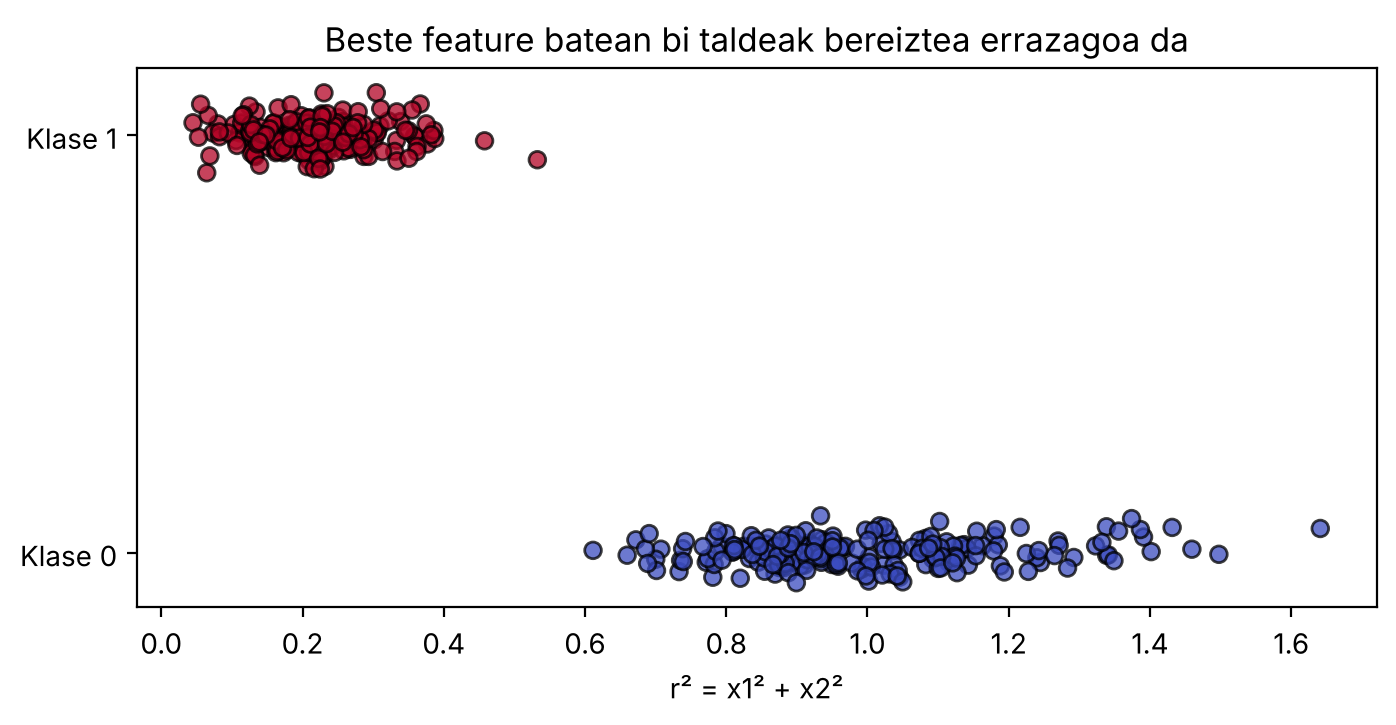

In [10]:
# Kernel-trick intuiziorako feature sinple bat:
# r² = x1² + x2²
r2 = Xc[:, 0]**2 + Xc[:, 1]**2

# y ardatzean jitter txiki bat, puntuak hobeto ikusteko
rng = np.random.default_rng(42)
jitter = rng.normal(0, 0.035, size=len(yc))

plt.figure(figsize=(8, 3.5))
plt.scatter(
    r2,
    yc + jitter,
    c=yc,
    cmap='coolwarm',
    edgecolors='k',
    alpha=0.75
)

plt.yticks([0, 1], ['Klase 0', 'Klase 1'])
plt.xlabel('r² = x1² + x2²')
plt.title('Beste feature batean bi taldeak bereiztea errazagoa da')
plt.show()


## 3.2 — RBF kernela 🟡

RBF kernelak puntuen arteko antzekotasuna/distantzia erabiltzen du modu ez-linealean.

Ondorioz:

```text
feature-space aberatsagoa
↓
SVM-k bereizketa egin
↓
jatorrizko 2D grafikoan
↓
muga kurboa ikus dezakegu
```

Beraz esaldi zehatzagoa da:

> **RBF kernelak ez du “kurba bat zuzenean marrazten”; SVM-ri muga ez-lineala lortzeko aukera ematen dio.**


SVM RBF TEST accuracy: 1.0


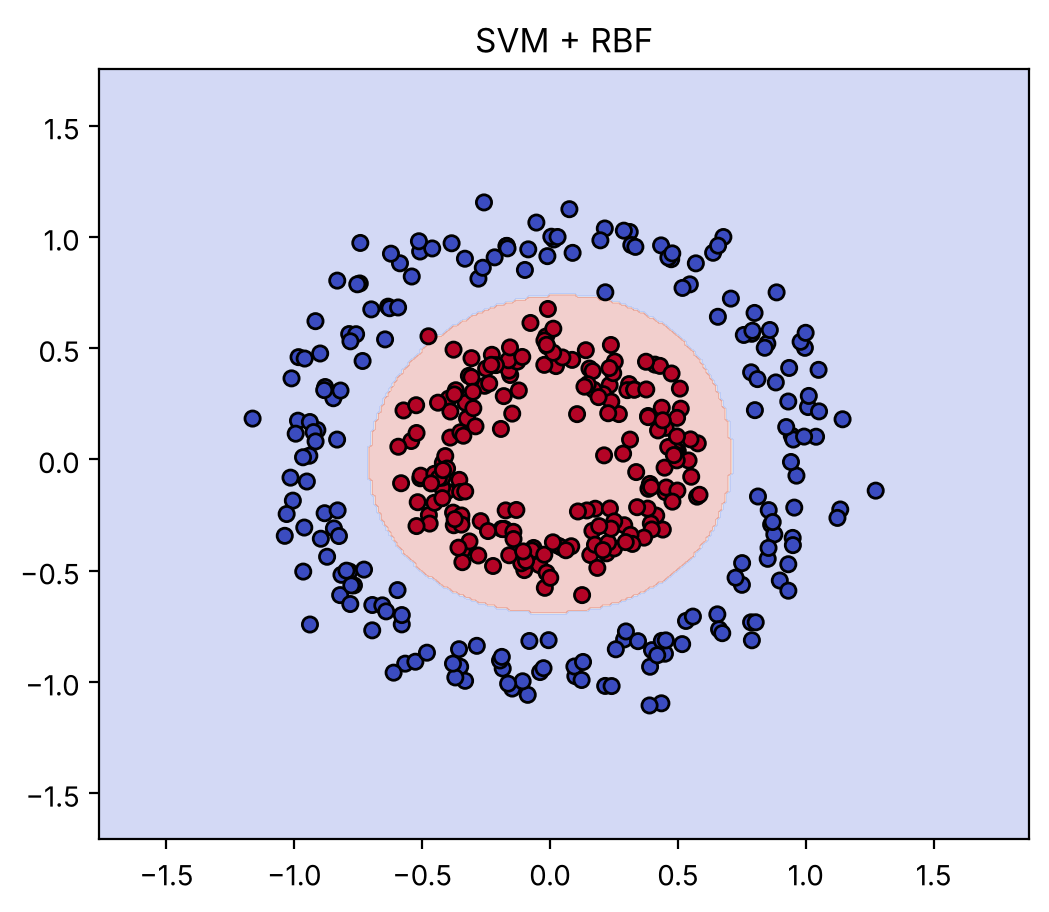

In [11]:
# bete ____ : RBF kernela
svm_rbf = SVC(kernel='rbf')
svm_rbf.fit(Xc_tr, yc_tr)

print(
    'SVM RBF TEST accuracy:',
    round(svm_rbf.score(Xc_te, yc_te), 3)
)

fig, ax = plt.subplots(figsize=(6, 5))
marraztu_muga(
    svm_rbf,
    Xc,
    yc,
    'SVM + RBF',
    ax
)
plt.show()


## 3.2.1 — RBF-k ere marjina eta euskarri-bektoreak ditu 🟢

Orain ideia garrantzitsu bat itxiko dugu.

SVM linealean ikusi dugu:

```text
marjina
────────────
erabaki-muga
────────────
marjina

+ support vectors
```

RBF kernela erabiltzean **SVM ez da beste algoritmo bat bihurtzen**.

Oraindik:

```text
1. erabaki-muga bat dago
2. marjinak daude
3. support vectors / euskarri-bektoreak daude
```

Aldea hau da:

> **Feature-space aberatsago batean bereizketa lineala izan daiteke, baina jatorrizko 2D espazioan muga eta marjinak kurboak ikus ditzakegu.**

Hurrengo grafikoan:

```text
lerro jarraitua  → decision boundary (`score = 0`)
lerro etenak     → marginak (`score = -1` eta `score = +1`)
zirkulu handiak  → support vectors
```

Beraz:

> **Kernelarekin ere SVM-k marjina eta euskarri-bektoreak erabiltzen ditu.**


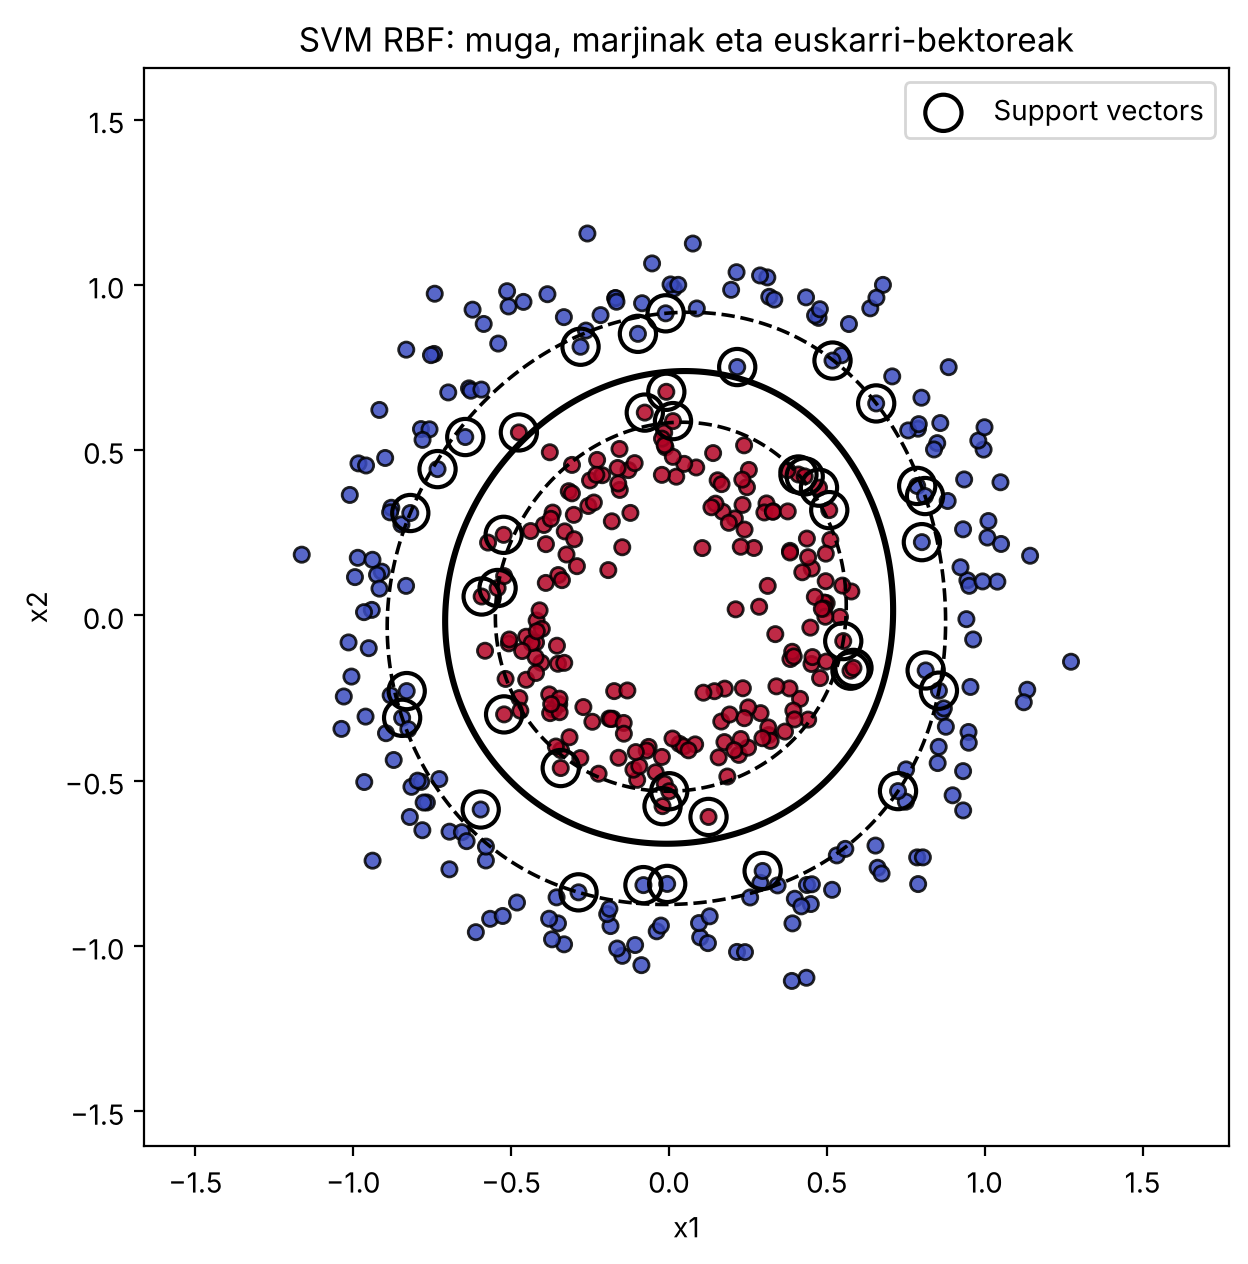

Support vector kopurua: 41


In [12]:
# svm_rbf aurreko atalean entrenatu dugu.
#
# Orain predict() eremuak margotu beharrean,
# decision_function() erabiliko dugu:
#
# score = -1  -> marjinaren alde bat
# score =  0  -> erabaki-muga
# score = +1  -> marjinaren beste aldea

fig, ax = plt.subplots(figsize=(7, 7))

x_min = Xc[:, 0].min() - 0.5
x_max = Xc[:, 0].max() + 0.5
y_min = Xc[:, 1].min() - 0.5
y_max = Xc[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Sareko puntu bakoitzaren decision score-a
Z = svm_rbf.decision_function(grid).reshape(xx.shape)

# Jatorrizko datuak
ax.scatter(
    Xc[:, 0],
    Xc[:, 1],
    c=yc,
    cmap='coolwarm',
    edgecolors='k',
    s=30,
    alpha=0.85
)

# -1 eta +1 -> marginak
#  0        -> decision boundary
ax.contour(
    xx,
    yy,
    Z,
    levels=[-1, 0, 1],
    colors='black',
    linestyles=['--', '-', '--'],
    linewidths=[1.3, 2.2, 1.3]
)

# Support vectors zirkulu handi batekin nabarmendu
ax.scatter(
    svm_rbf.support_vectors_[:, 0],
    svm_rbf.support_vectors_[:, 1],
    s=170,
    facecolors='none',
    edgecolors='black',
    linewidths=1.5,
    label='Support vectors'
)

ax.set_title('SVM RBF: muga, marjinak eta euskarri-bektoreak')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.legend()

plt.show()

print('Support vector kopurua:', len(svm_rbf.support_vectors_))


### Nola irakurri grafikoa?

Grafiko honetan bi ideia ikus daitezke aldi berean:

```text
SVM lineala:
muga eta marginak → zuzenak

SVM + RBF:
muga eta marginak → kurboak izan daitezke
```

Baina algoritmoaren oinarrizko ideia ez da aldatu:

```text
support vectors
↓
marjina
↓
decision boundary
```

Hau da kernelaren erabileraren ideia nagusia:

> **Jatorrizko datuak linealki bereizgarriak ez badira ere, kernelak SVM-ri bere marjina-printzipioa erabiltzen jarraitzea ahalbidetzen dio.**


## 3.3 — `gamma`: RBF-ren eragin lokala 🔴

`gamma` RBF kernelaren parametro garrantzitsua da.

Intuizioa:

```text
gamma TXIKIA
→ puntu baten eragina urrunago iristen da
→ muga leunagoa

gamma HANDIA
→ puntu baten eragina oso lokala da
→ muga konplexuagoa
→ overfitting arrisku handiagoa
```

Gogoratzeko bikotea:

```text
C     → zenbat zigortu training akatsak?
gamma → RBF-k zenbat lokalki begiratu?
```

Konparatu `gamma = 0.1, 1, 10`.


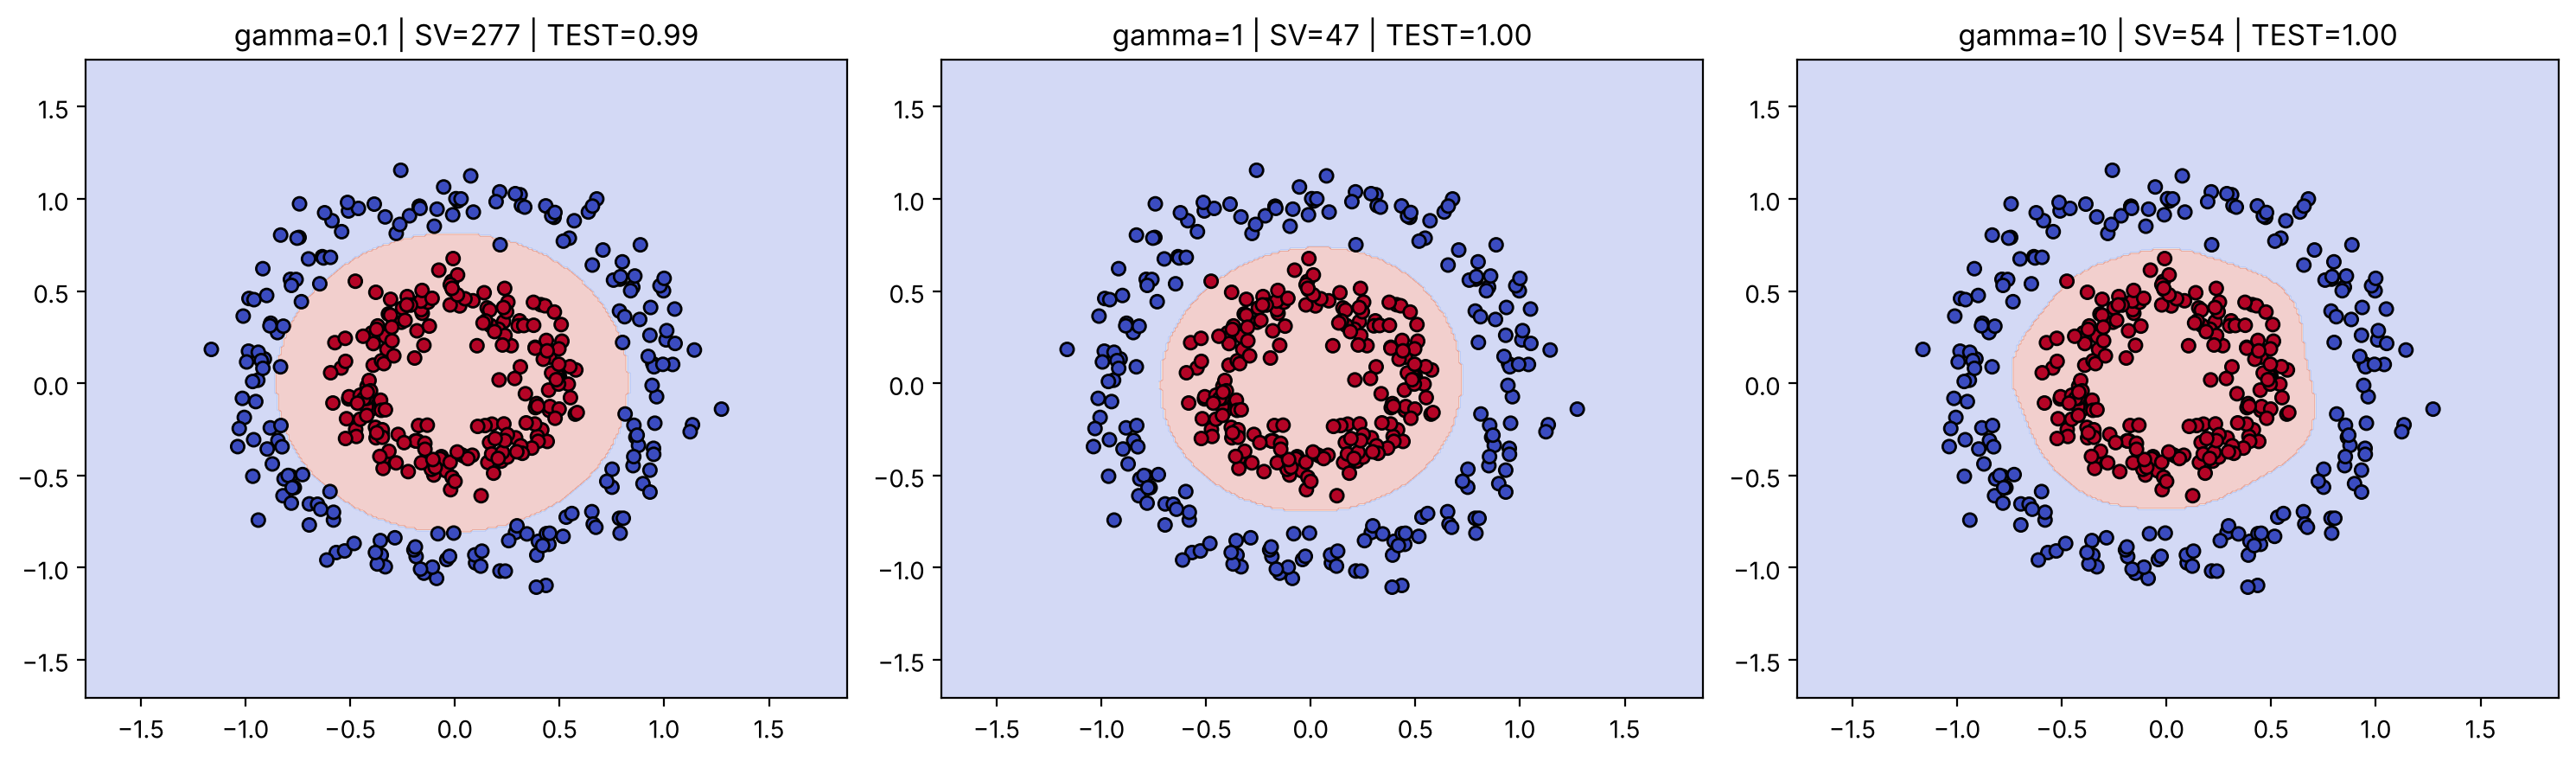

In [13]:
gamma_balioak = [0.1, 1, 10]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, g in zip(axes, gamma_balioak):
    # RBF SVM gamma desberdinarekin (C default = 1)
    modeloa = SVC(kernel='rbf', gamma=g)
    modeloa.fit(Xc_tr, yc_tr)

    acc = modeloa.score(Xc_te, yc_te)

    marraztu_muga(
        modeloa,
        Xc,
        yc,
        f'gamma={g} | SV={len(modeloa.support_vectors_)} | TEST={acc:.2f}',
        ax
    )

plt.tight_layout()
plt.show()

# 4 ATALA — Titanic: SVM benetako datuekin 🟢🟡

Orain datu errealetara itzuliko gara.

Ezaugarriak:

```text
pclass
sex
age
fare
embarked
```

Target-a:

```text
survived
```

## Preprocessing arau garrantzitsua

Aurreko unitateetan ikasi dugun araua mantenduko dugu:

> **Datuetatik parametro bat ikasten duen preprocessing urratsa → TRAIN bakarrik.**

Beraz:

```text
Titanic
↓
TRAIN / TEST
↓
TRAIN median/mode
↓
TRAIN eta TEST bete
↓
One-Hot Encoding
↓
StandardScaler fit TRAIN
↓
transform TRAIN + TEST
```

Ez dugu medianarik edo scaler parametrorik TEST-etik ikasiko.


In [14]:
# Colab-en internet konexioa behar du.
df = sns.load_dataset('titanic')

d = df[
    ['survived', 'pclass', 'sex', 'age', 'fare', 'embarked']
].copy()

d.head()


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## 4.1 — Zergatik da eskalatzea garrantzitsua SVM-n? 🟢

SVM-ren marjina **geometrikoa** da.

Adibidez:

```text
age  → 0–80
fare → 0–500
```

eskalarik gabe, `fare`-k geometria gehiegi domina dezake.

KNN-rekin antzeko ideia ikusi genuen:

> **distantzia/geometria garrantzitsua denean, eskala garrantzitsua da.**

Ariketa honetan jarraituak diren zutabeak eskalatuko ditugu:

```text
pclass
age
fare
```

Dummy 0/1 zutabeak 0/1 bezala utziko ditugu.


In [15]:
# 1. Lehenengo TRAIN / TEST
train_df, test_df = train_test_split(
    d,
    test_size=0.2,
    random_state=42,
    stratify=d['survived']
)

train_df = train_df.copy()
test_df = test_df.copy()


# 2. TRAIN-etik bakarrik ikasi mediana eta moda
age_mediana = train_df['age'].median()
embarked_moda = train_df['embarked'].mode()[0]


# 3. Balio BERBERAK aplikatu TRAIN eta TEST-en
train_df['age'] = train_df['age'].fillna(age_mediana)
test_df['age'] = test_df['age'].fillna(age_mediana)

train_df['embarked'] = train_df['embarked'].fillna(embarked_moda)
test_df['embarked'] = test_df['embarked'].fillna(embarked_moda)


print('TRAIN nuluak:', train_df.isnull().sum().sum())
print('TEST nuluak :', test_df.isnull().sum().sum())


TRAIN nuluak: 0
TEST nuluak : 0


In [16]:
# Target
y_train = train_df['survived'].values
y_test = test_df['survived'].values

# X
X_train = train_df.drop(columns=['survived'])
X_test = test_df.drop(columns=['survived'])

# One-Hot
X_train = pd.get_dummies(
    X_train,
    columns=['sex', 'embarked'],
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=['sex', 'embarked'],
    drop_first=True
)

# TEST-ek TRAIN-en zutabe berdinak eta ordena bera izan behar du
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_train = X_train.astype(float)
X_test = X_test.astype(float)


# Eskalatu jarraituak / ordenatuak
num_cols = ['pclass', 'age', 'fare']

scaler = StandardScaler()

# bete ____ :
X_train[num_cols] = scaler.fit_transform(
    X_train[num_cols]
)

X_test[num_cols] = scaler.transform(
    X_test[num_cols]
)

print('TRAIN shape:', X_train.shape)
print('TEST shape :', X_test.shape)
print('Zutabeak:', list(X_train.columns))


TRAIN shape: (712, 6)
TEST shape : (179, 6)
Zutabeak: ['pclass', 'age', 'fare', 'sex_male', 'embarked_Q', 'embarked_S']


## 4.2 — Logistic vs SVM lineala vs SVM RBF 🟡

Datu berdinekin hiru modelo alderatuko ditugu:

```text
Logistic Regression
SVM linear
SVM RBF
```

Ez begiratu accuracy bakarrik.

SVM-n interesgarria da ere:

```python
svm.n_support_
```

klase bakoitzean zenbat support vector erabili diren ikustea.


In [17]:
# Hiru modelo
log = LogisticRegression(max_iter=1000)

svm_linear = SVC(
    kernel='linear'
)

svm_rbf = SVC(
    kernel='rbf'
)

modeloak = [
    ('Logistika', log),
    ('SVM lineala', svm_linear),
    ('SVM RBF', svm_rbf)
]

for izena, modeloa in modeloak:

    modeloa.fit(X_train, y_train)

    acc = modeloa.score(
        X_test,
        y_test
    )

    print(f'{izena:12s} TEST accuracy: {acc:.3f}')


print('\nRBF support vectors klase bakoitzean:')
print(svm_rbf.n_support_)

print(
    'Guztira:',
    svm_rbf.n_support_.sum()
)


Logistika    TEST accuracy: 0.771
SVM lineala  TEST accuracy: 0.777
SVM RBF      TEST accuracy: 0.810

RBF support vectors klase bakoitzean:
[174 168]
Guztira: 342


## Titanic emaitzen interpretazioa: zer ikasi behar dugu hemen? 🟢

Notebook honetan, konfigurazio honekin, gutxi gorabehera hau lortzen dugu:

```text
Logistika    TEST accuracy ≈ 0.771
SVM lineala  TEST accuracy ≈ 0.777
SVM RBF      TEST accuracy ≈ 0.810
```

Lehen begiratuan ikasle batek hau pentsa dezake:

> **“RBF konplexuagoa da; beraz konplexuagoa beti hobea da.”**

Baina hori **EZ** da ondorio zuzena.

### 1. Titanic ez dugu “dataset lineala” bezala definituko

Hobe esatea:

> **Gure feature-ekin, eredu linealek Titanic-en informazio erabilgarri asko harrapatzen dute, baina baliteke feature-en arteko erlazio ez-lineal batzuk ere erabilgarriak izatea.**

Adibidez:

```text
sex
pclass
age
fare
```

feature-en eragina ez da zertan guztiz independentea edo lineala izan.

Beraz RBF-k duen malgutasun gehigarriak **esperimentu honetan** lagundu dezake.

### 2. Logistic Regression eta SVM lineala biak dira linealak

Bi modeloek feature-space-an muga lineala sortzen dute, baina **helburu desberdinekin** entrenatzen dira:

```text
LOGISTIC REGRESSION
→ probabilitateak
→ Log Loss
→ koefizienteak optimizatu

SVM LINEALA
→ margin handia
→ support vectors
→ margin violations kontrolatu
```

Horregatik ez dute zertan muga berdina aurkitu, ezta TEST accuracy berdina ere.

### 3. RBF-k aukera gehiago ditu, baina horrek ez du esan nahi beti hobea denik

RBF-k decision boundary ez-linealak sor ditzake:

```text
Linear:
----------------

RBF:
~~~~~ kurboagoa / lokalagoa ~~~~~
```

Datuen egiturak malgutasun hori behar badu, RBF lagungarria izan daiteke.

Baina gehiegizko malgutasunak:

```text
training datuetara gehiegi egokitu
↓
TRAIN accuracy oso handia
↓
TEST ez hobetu edo okertu
```

eragin dezake.

### 4. Beraz, zer esan dezakegu gure emaitzez?

Esaldi zuzena:

> **“TRAIN/TEST banaketa honetan eta parametro hauekin, RBF SVM-k TEST accuracy handiena lortu du.”**

Ez esan:

> ❌ “RBF da Titanic-erako algoritmo onena.”

Horretarako beste gauza batzuk beharko genituzke:

```text
cross-validation
+
hyperparameter tuning
+
beste metric batzuk
```

Orain galdera interesgarria hau da:

> **RBF gero eta konplexuago egiten badugu, TEST accuracy beti igoko al da?**

Hurrengo esperimentuak hori aztertuko du.


## Titanic-en `gamma` esperimentua: konplexuagoa ≠ beti hobea 🟡

RBF SVM-n `gamma` parametroak puntu bakoitzaren eragin-eremua kontrolatzen du:

```text
gamma txikia
→ eragin zabalagoa
→ boundary leunagoa
→ underfitting arriskua

gamma handia
→ eragin lokalagoa
→ boundary konplexuagoa
→ overfitting arriskua
```

Orain `C=1` finko utziko dugu eta `gamma` bakarrik aldatuko dugu:

```text
0.001
0.01
0.1
1
10
100
```

Zergatik aldagai bakarra?

> **Parametro bakarraren efektua ikusteko.**

Bi kurba marraztuko ditugu:

```text
TRAIN accuracy
TEST accuracy
```

Begiratu ea honelako zerbait gertatzen den:

```text
gamma oso txikia
→ TRAIN eta TEST baxuago
→ modeloa sinpleegia izan daiteke

gamma ertaina
→ TEST hobea
→ konplexutasun erabilgarria

gamma oso handia
→ TRAIN oso altua
→ TEST ez da zertan hobetu
→ overfitting posible
```

Garrantzitsuena ez da balio zehatz bat memorizatzea.

Garrantzitsuena:

> **Model complexity datuen egiturarekin egokitu behar da.**


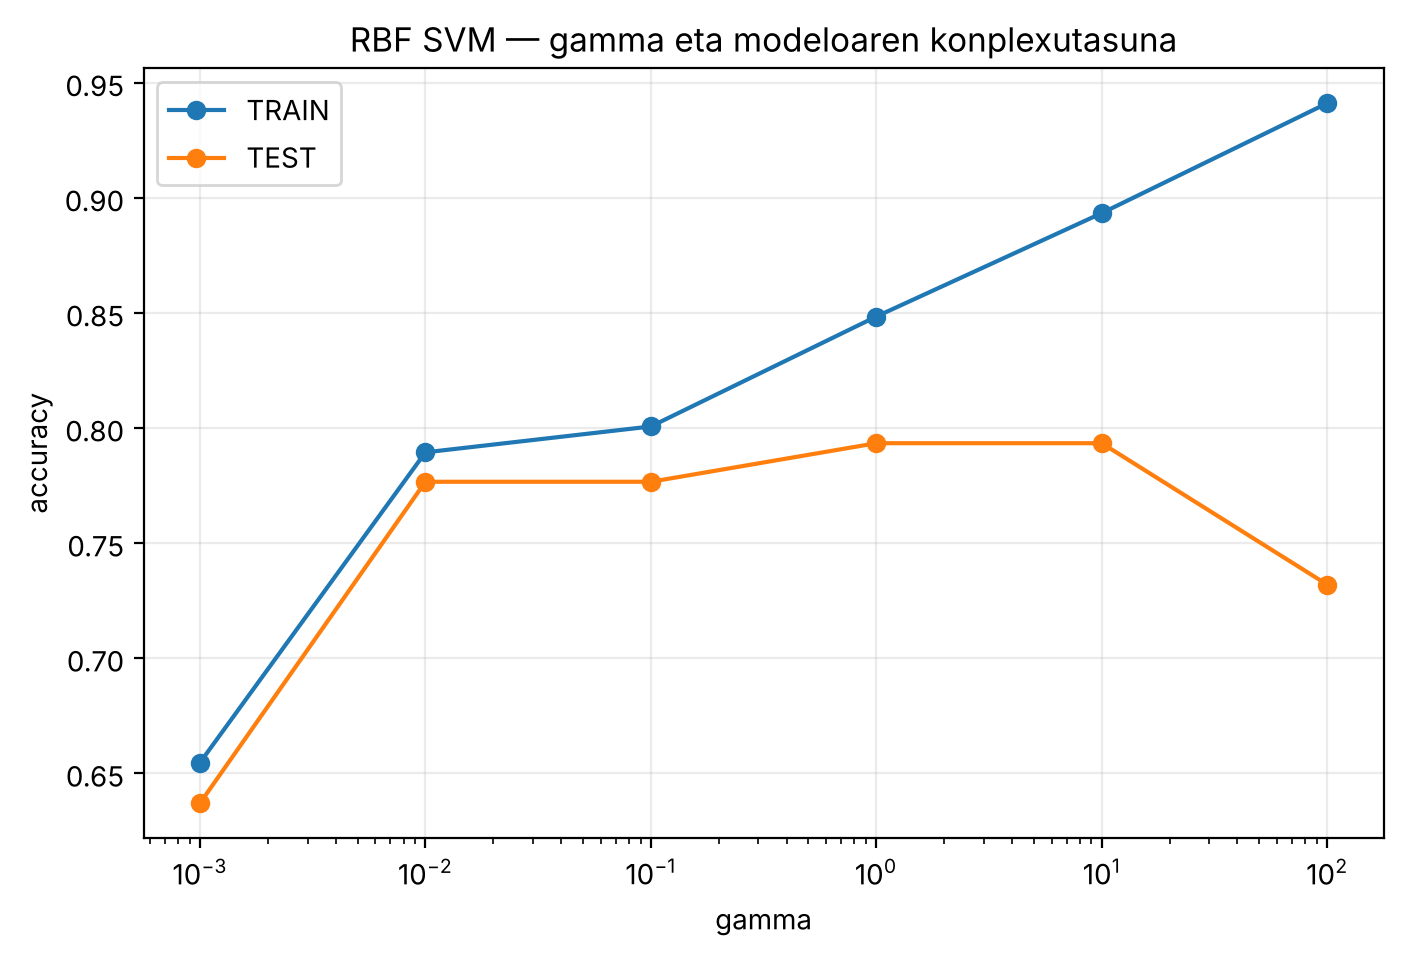

gamma=0.001  TRAIN=0.654  TEST=0.637
gamma=0.01   TRAIN=0.789  TEST=0.777
gamma=0.1    TRAIN=0.801  TEST=0.777
gamma=1      TRAIN=0.848  TEST=0.793
gamma=10     TRAIN=0.893  TEST=0.793
gamma=100    TRAIN=0.941  TEST=0.732


In [18]:
# C finko uzten dugu (C=1) eta gamma bakarrik aldatzen dugu.

gammas = [0.001, 0.01, 0.1, 1, 10, 100]

train_scores = []
test_scores = []

for g in gammas:

    modeloa = SVC(
        kernel='rbf',
        C=1,
        gamma=g
    )

    # SVM-k scaling behar du (lehendik eskalatuta dago X_train-en)
    modeloa.fit(
        X_train,
        y_train
    )

    train_scores.append(
        modeloa.score(X_train, y_train)
    )

    test_scores.append(
        modeloa.score(X_test, y_test)
    )


plt.figure(figsize=(8, 5))

plt.semilogx(
    gammas,
    train_scores,
    marker='o',
    label='TRAIN'
)

plt.semilogx(
    gammas,
    test_scores,
    marker='o',
    label='TEST'
)

plt.xlabel('gamma')
plt.ylabel('accuracy')
plt.title('RBF SVM — gamma eta modeloaren konplexutasuna')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

for g, tr, te in zip(gammas, train_scores, test_scores):
    print(f'gamma={g:<6} TRAIN={tr:.3f}  TEST={te:.3f}')

### Interpretatzeko galderak

Grafikoa ikusi ondoren:

1. `gamma` oso txikiarekin TRAIN eta TEST emaitzak nolakoak dira?
2. Zein `gamma` ingurutan lortzen da TEST emaitzarik onena **esperimentu honetan**?
3. `gamma` handitzen denean TRAIN accuracy-k zer joera du?
4. TEST accuracy-k joera bera al du beti?
5. TRAIN oso altua baina TEST txikiagoa bada, zer susma dezakegu?
6. Beraz, hau zuzena al da?

```text
"gamma handiagoa = modelo hobea"
```

Erantzuna:

> **Ez. gamma handiagoak modelo malguago/lokalago bat sor dezake, baina malgutasun gehigarriak ez du zertan generalizazioa hobetu.**

Eta hau da ikasgai nagusia:

> **Konplexuagoa ≠ automatikoki hobea.**


### Erantzunak (esperimentu honetako emaitzekin)

1. **gamma oso txikiarekin** (0.001) bai TRAIN (0.654) bai TEST (0.637) baxuak dira → modeloa **sinpleegia** (underfitting).
2. TEST onena **gamma = 1 eta 10** inguruan lortzen da (0.793).
3. gamma handitzean TRAIN accuracy **etengabe igotzen** da (0.654 → 0.941).
4. **Ez.** TEST igo egiten da gamma=1/10 arte, eta gero **jaitsi** egiten da (gamma=100 → 0.732).
5. TRAIN oso altua (0.941) eta TEST txikiagoa (0.732) → **overfitting** susma dezakegu: muga oso lokala da eta train-eko puntuak buruz ikasten ditu.
6. **Ez da zuzena.** gamma handiagoak modelo malguagoa ematen du, baina malgutasun gehiegiak generalizazioa okertzen du.

## 4.3 — Confusion Matrix 🟢

Accuracy globalaz gain, ikusiko dugu:

```text
TN  FP
FN  TP
```

SVM RBF-ren iragarpenekin confusion matrix marraztuko dugu.


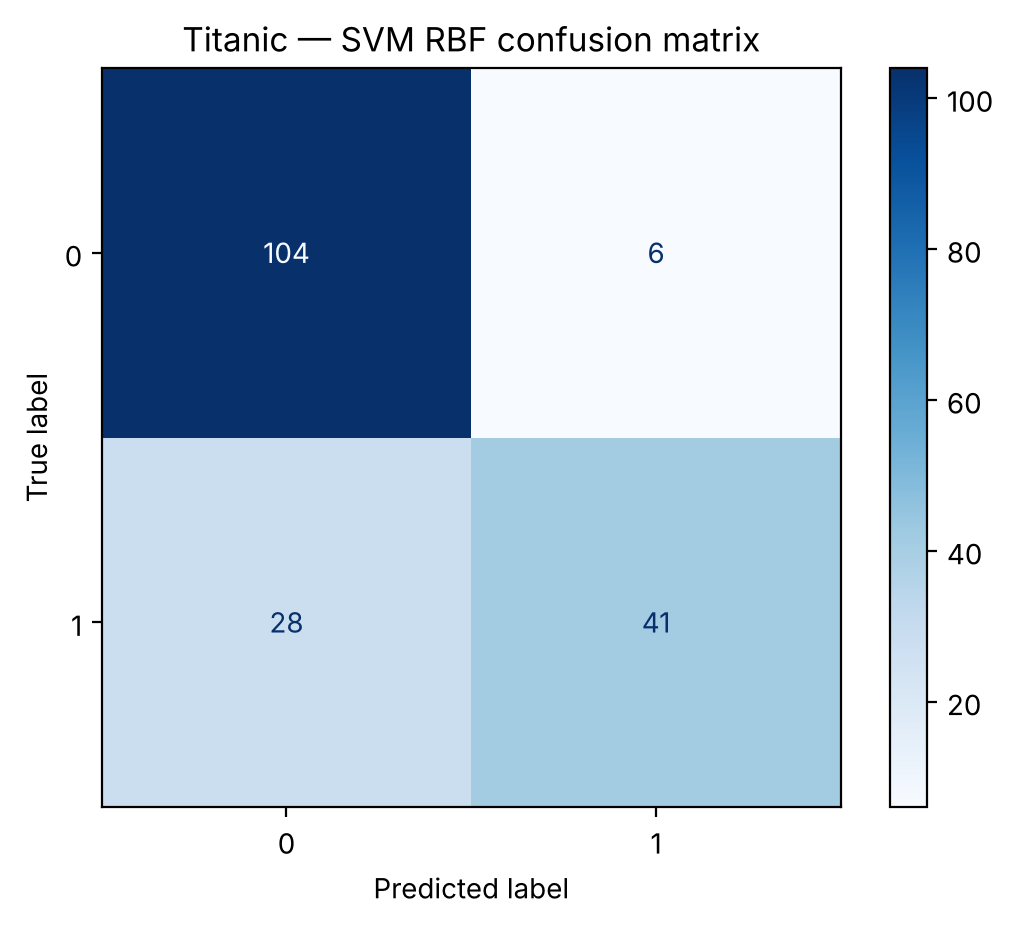

In [19]:
y_pred_rbf = svm_rbf.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rbf,
    cmap='Blues'
)

plt.title('Titanic — SVM RBF confusion matrix')
plt.show()


# 5 ATALA — Azken konparazioa

| Eredua | Nola ikasten du? | Eskalatzea | Ez-linealtasuna |
|---|---|---|---|
| Erabaki-zuhaitza | arauak / split-ak | normalean ez | bai |
| KNN | auzokideak / distantziak | **bai** | bai |
| Logistic Regression | Log Loss + koefizienteak | gomendatua | ez, oinarrizko forman |
| SVM lineala | marjina maximoa | **bai** | ez |
| SVM + RBF | marjina + kernel | **bai** | **bai** |

### SVM-rako 5 ideia nagusi

```text
1. Decision boundary
2. Maximum margin
3. Support vectors
4. C
5. Kernel + gamma
```

Eta gogoratu:

> **Kernel bat ez da “marra kurbo bat”. Datuen arteko erlazioa beste feature-space batean modelatzeko tresna da.**


## Hausnarketa amaierakoa

1. Zergatik ez du SVM-k probabilitatea behar muga ikasteko?

SVM ez da probabilitateak ($P(Y\vert{}X)$) estimatzen dituen eredu estatistiko bat. Geometrian oinarritzen da: klaseak bereizten dituen hiperplanoa bilatzen du, klase ezberdinetako puntu hurbilenen arteko tartea (marjina) maximizatuz.

2. Zer puntu dira support vectors?

Mugatik gertuen dauden puntu guztiak dira (edo marjinaren muga/barrualdean geratzen direnak). Puntu hauek bakarrik zehazten dute banaketa-mugaren posizioa eta orientazioa; gainerako puntuak ezabatuko balira, muga ez litzateke aldatuko.

3. Zer kontrolatzen du `C`-k?

Marjinaren zabaleraren eta sailkapen-erroreen arteko oreka kontrolatzen du:

$C$ altua (margen gogorra): Entrenamendu-akatsak minimizatzea du helburu. Muga zorrotzagoa eta konplexuagoa da (overfitting arriskua).

$C$ baxua (margen biguna): Marjina zabalagoa lehenesten du, akats batzuk onartuz. Muga bakunagoa eta orokorragoa da.

4. Zergatik huts egiten du SVM linealak `make_circles`-en?

make_circles bidez sortutako datuak zirkulu zentrokideak dira eta ez dira linealki bereizgarriak. Hiperplano lineal batek (2Dn zuzen batek) ezin ditu bi zirkulu kontzentriko bereizi espazioaren dimentsioa eraldatu gabe.

5. Zer ekartzen du RBF kernelak?

Datuak dimentsio altuagoko (edo infinituko) espazio batera proiektatzen ditu inplizituki, antzekotasun gaussiarrean oinarrituta. Honi esker, jatorrizko 2D espazioan muga ez-lineal eta zakarrak marraz ditzake.

6. Zer kontrolatzen du `gamma`-k?

Euskarri-bektore bakoitzaren eragin-erradioa kontrolatzen du:

$\gamma$ altua: Eragina oso tokikoa da (puntu bakoitzaren inguruan muga oso zehatza marrazten da, overfitting sortuz).

$\gamma$ baxua: Eragin-erradioa handia da, muga oso leun eta orokorrak sortuz (underfitting sortzeko arriskuz).

7. Zergatik eskalatzen dugu Titanic-en?

SVMk puntuen arteko distantzia geometrikoak kalkulatzen ditu. Eskalatu gabe, balio-tarte handiko ezaugarriek (Fare: 0-500) distantziaren kalkulua erabat menperatuko lukete tarte txikiagoko ezaugarrien kalterako (Age: 0-80 edo Pclass: 1-3). Eskalatzeak aldagai guztiei pisu bera ematen die.
